# Data preparation: census and map data for Hungary, Georgia and Nepal

This notebook turns the raw downloads in `data/raw/` into the two clean files that Tableau uses, in `data/processed/`:

| Output | Content |
|---|---|
| `HU-GE-NE_census.csv` | One row per country × region × 5-year age group × sex, with the population at both censuses and the row-level features |
| `HU-GE-NE_map.geojson` | One simplified polygon per region (Hungary 20, Georgia 12 incl. Abkhazia, Nepal 75), with `Country` and `Map_key` to join to the census table |

**How to run:** open the notebook with the kernel **Python (UGST4096)** and run all cells from top to bottom. Every step first explains what it does (markdown), then does it (code), then shows the result (output). The definitions follow `appendix.md` and `data/processed/codebook.md`.

**Steps**

- Part 0: setup (steps 1–4)
- Part A: census data (steps 5–21)
- Part B: map data (steps 22–28)
- Part C: final check of both outputs together (step 29)

## Part 0: Setup

### Step 1: Install the libraries

The environment `UGST4096` starts almost empty, so the first cell installs every library the notebook needs:

| Library | Used for |
|---|---|
| `pandas` | tables |
| `openpyxl` | reading Excel files (Hungary 2022/2011, Nepal 2011) |
| `pdfplumber` | reading text from the Nepal 2021 PDF report |
| `geopandas`, `shapely`, `pyogrio` | reading, merging, simplifying and writing map files |
| `matplotlib` | drawing the small preview map at the end |

Running it again is harmless: pip skips libraries that are already installed.

In [1]:
# install all libraries the notebook needs into the active environment (ugst4096)
%pip install pandas openpyxl pdfplumber geopandas shapely pyogrio matplotlib

Note: you may need to restart the kernel to use updated packages.


### Step 2: Import the libraries

Load the installed libraries, and a few tools from Python's own standard library (`re` for text patterns, `unicodedata` for removing accents, `pathlib` for file paths).

In [2]:
# import re, the standard tool for matching text patterns (used to read the pdf lines)
import re

# import unicodedata, the standard tool for removing accents from letters (used for hungarian map names)
import unicodedata

# import path, the standard tool for building file paths that work on every computer
from pathlib import Path

# import pandas, the library for tables, under the short name pd
import pandas as pd

# import openpyxl, the library that reads excel files cell by cell
import openpyxl

# import pdfplumber, the library that reads the text of pdf pages
import pdfplumber

# import geopandas, the library for tables with map shapes, under the short name gpd
import geopandas as gpd

# import shapely, the library for geometry operations (checking and counting shape points)
import shapely

# print the library versions so the run can be repeated with the same versions
print("pandas", pd.__version__, "| openpyxl", openpyxl.__version__, "| pdfplumber", pdfplumber.__version__, "| geopandas", gpd.__version__, "| shapely", shapely.__version__)

pandas 3.1.0 | openpyxl 3.1.5 | pdfplumber 0.11.10 | geopandas 1.2.0 | shapely 2.2.0


### Step 3: Set the folders and file names

The notebook lives in `prep/`, so the project folder is one level up. All inputs are read from `data/raw/` and all outputs are written to `data/processed/`. The cell stops with an error if any input file is missing.

In [3]:
# the project folder is the parent of the folder this notebook runs in (prep)
PROJECT = Path.cwd().parent

# the folder with the raw census files
RAW_CENSUS = PROJECT / "data" / "raw" / "census"

# the folder with the raw map files
RAW_GEO = PROJECT / "data" / "raw" / "geo"

# the folder where the clean outputs are written
PROCESSED = PROJECT / "data" / "processed"

# create the output folder if it does not exist yet
PROCESSED.mkdir(parents=True, exist_ok=True)

# the nepal 2021 census report (pdf) that holds table 18
NEPAL_2021_PDF = RAW_CENSUS / "Population Census_National Report_English.pdf"

# the folder with the 75 unpacked nepal 2011 district workbooks
NEPAL_2011_DIR = RAW_CENSUS / "district-profile-census-2011"

# the georgia 2014 census table
GEORGIA_2014_CSV = RAW_CENSUS / "georgia_2014_pop_age_sex_mkhare.csv"

# the georgia 2024 census table
GEORGIA_2024_CSV = RAW_CENSUS / "georgia_2024_pop_age_sex_mkhare.csv"

# the hungary census table (2001, 2011, 2022) as excel export
HUNGARY_XLSX = RAW_CENSUS / "hungary_2001-2011-2022_pop_age_sex_varmegye.xlsx"

# the hungary map (hdx), a zip file with geojson layers inside
HUNGARY_MAP_ZIP = RAW_GEO / "hun_admin_boundaries.geojson.zip"

# the georgia map (geoboundaries), a zip file with geojson layers inside
GEORGIA_MAP_ZIP = RAW_GEO / "geoBoundaries-GEO-ADM1-all.zip"

# the nepal map (hdx), a zip file with geojson layers inside
NEPAL_MAP_ZIP = RAW_GEO / "npl_admin_boundaries.geojson.zip"

# the census output file
CENSUS_OUT = PROCESSED / "HU-GE-NE_census.csv"

# the map output file
MAP_OUT = PROCESSED / "HU-GE-NE_map.geojson"

# list every input so they can be checked in one loop
inputs = [NEPAL_2021_PDF, NEPAL_2011_DIR, GEORGIA_2014_CSV, GEORGIA_2024_CSV, HUNGARY_XLSX, HUNGARY_MAP_ZIP, GEORGIA_MAP_ZIP, NEPAL_MAP_ZIP]

# go through the inputs one by one
for p in inputs:

    # stop with an error message if the input does not exist
    assert p.exists(), f"missing input: {p}"

    # print the input name to show it was found
    print("found:", p.relative_to(PROJECT))

found: data\raw\census\Population Census_National Report_English.pdf
found: data\raw\census\district-profile-census-2011
found: data\raw\census\georgia_2014_pop_age_sex_mkhare.csv
found: data\raw\census\georgia_2024_pop_age_sex_mkhare.csv
found: data\raw\census\hungary_2001-2011-2022_pop_age_sex_varmegye.xlsx
found: data\raw\geo\hun_admin_boundaries.geojson.zip
found: data\raw\geo\geoBoundaries-GEO-ADM1-all.zip
found: data\raw\geo\npl_admin_boundaries.geojson.zip


### Step 4: Shared settings from the plan

These values are shared by all three countries and are used in all later steps:

- **Census years and $t$:** $t$ = latest census year − previous census year.
- **16 age groups:** `0-4` … `70-74` and the open top group `75+` (Nepal 2011 stops there), with a sort number `Age_order` (1–16) and a broad band `Age_band` (0–14, 15–64, 65+).
- **Capital flags (appendix A9):** `Capital_city` = the capital alone; `Capital_area` = the wider capital area.
- **Official national totals** used for the checks: the totals printed in the sources themselves are read in later steps; only Nepal 2011's national total (26 494 504, NSO 2011 census) is typed in here, because the district workbooks have no national row.

In [4]:
# the previous and latest census year of each country (d3)
CENSUS_YEARS = {"Hungary": (2011, 2022), "Georgia": (2014, 2024), "Nepal": (2011, 2021)}

# the years between the two censuses, t = latest year minus previous year (d3)
T_YEARS = {country: latest - previous for country, (previous, latest) in CENSUS_YEARS.items()}

# all census years that become columns of the output, in time order
YEAR_COLUMNS = [2011, 2014, 2021, 2022, 2024]

# the 15 closed 5-year groups from 0-4 to 70-74, written like "0-4"
CLOSED_GROUPS = [f"{a}-{a + 4}" for a in range(0, 75, 5)]

# the 16 age groups of the output: the closed groups plus the open top group 75+
AGE_GROUPS = CLOSED_GROUPS + ["75+"]

# the sort number of each age group, 1 for 0-4 up to 16 for 75+
AGE_ORDER = {group: i + 1 for i, group in enumerate(AGE_GROUPS)}

# the broad band of each age group: 0-14 for the first 3 groups, 65+ for the last 3, 15-64 in between
AGE_BAND = {group: ("0-14" if AGE_ORDER[group] <= 3 else "65+" if AGE_ORDER[group] >= 14 else "15-64") for group in AGE_GROUPS}

# the capital city of each country (d5 option 1)
CAPITAL_CITY = {"Hungary": {"Budapest"}, "Georgia": {"Tbilisi"}, "Nepal": {"Kathmandu"}}

# the wider capital area of each country (d5 option 2)
CAPITAL_AREA = {"Hungary": {"Budapest", "Pest"}, "Georgia": {"Tbilisi"}, "Nepal": {"Kathmandu", "Lalitpur", "Bhaktapur"}}

# nepal's official 2011 national total (nso, census 2011), used only to check the district sum
NEPAL_2011_NATIONAL_TOTAL = 26494504

# print the settings to see them
print("t (years):", T_YEARS)

# print the age groups with their sort number and band
print({g: (AGE_ORDER[g], AGE_BAND[g]) for g in AGE_GROUPS})

t (years): {'Hungary': 11, 'Georgia': 10, 'Nepal': 10}
{'0-4': (1, '0-14'), '5-9': (2, '0-14'), '10-14': (3, '0-14'), '15-19': (4, '15-64'), '20-24': (5, '15-64'), '25-29': (6, '15-64'), '30-34': (7, '15-64'), '35-39': (8, '15-64'), '40-44': (9, '15-64'), '45-49': (10, '15-64'), '50-54': (11, '15-64'), '55-59': (12, '15-64'), '60-64': (13, '15-64'), '65-69': (14, '65+'), '70-74': (15, '65+'), '75+': (16, '65+')}


## Part A: Census data

Each country is read from its raw file, checked against the totals printed in the source, and brought into the same **long format**: one row per region × age group × sex × census year, with the columns `Country`, `Region`, `Age_group`, `Sex`, `Year`, `Population`. The four country tables are then combined, reshaped and given their features.

### Step 5: Nepal 2021, read the text of Table 18 from the PDF

Table 18 (*Population by five year age groups and sex, NPHC 2021*) is on report pages 84–135, which are **PDF pages 99–150** (the report's page numbers start after 15 front pages). `pdfplumber` reads the text of each page as lines; all lines of the 52 pages are collected into one list.

In [5]:
# the first and last pdf page of table 18 (pdf page numbers, counted from 1)
FIRST_PAGE, LAST_PAGE = 99, 150

# an empty list that will collect the text lines of all pages
pdf_lines = []

# open the pdf file
with pdfplumber.open(NEPAL_2021_PDF) as pdf:

    # go through the table 18 pages (pdfplumber counts pages from 0, so subtract 1)
    for page in pdf.pages[FIRST_PAGE - 1:LAST_PAGE]:

        # read the page text and split it into lines, then add them to the list
        pdf_lines.extend(page.extract_text().splitlines())

# print how many lines were read
print(len(pdf_lines), "lines read from", LAST_PAGE - FIRST_PAGE + 1, "pages")

# print the first 12 lines to see what they look like
print("\n".join(pdf_lines[:12]))

2244 lines read from 52 pages
Table 18: Population by five year age groups and sex, NPHC 2021
Area and five years Total Male Female
age group
Number Percent Number Percent Number Percent
Nepal
All Ages 29164578 100.00 14253551 100.00 14911027 100.00
00-04 Yrs. 2439283 8.36 1290525 9.05 1148758 7.70
05-09 Yrs. 2766427 9.49 1443405 10.13 1323022 8.87
10-14 Yrs. 2909865 9.98 1495954 10.50 1413911 9.48
15-19 Yrs. 2966404 10.17 1494523 10.49 1471881 9.87
20-24 Yrs. 2783060 9.54 1301018 9.13 1482042 9.94
25-29 Yrs. 2459349 8.43 1122242 7.87 1337107 8.97


### Step 6: Nepal 2021, turn the text lines into a table

Every line of Table 18 is one of these kinds:

| Kind of line | Example | What the code does |
|---|---|---|
| Repeated page header or page number | `Table 18: …`, `Number Percent …`, `86` | skip |
| Section heading | `Province`, `District` | remember the level |
| Area name | `Kathmandu` | remember the area |
| Data line | `65-69 Yrs. 42720 2.09 20898 2.02 21822 2.17` | store area, age group, the three counts and the three percentages |

A **regular expression** (a text pattern) recognises the data lines: an age label (`00-04 Yrs.` … `95+ Yrs.` or `All Ages`) followed by six numbers: total, its percent, male, its percent, female, its percent.

In [6]:
# the pattern of a data line: age label, then count and percent for total, male and female
DATA_LINE = re.compile(r"^(All Ages|\d{2}-\d{2} Yrs\.|95\+ Yrs\.) (\d+) ([\d.]+) (\d+) ([\d.]+) (\d+) ([\d.]+)$")

# the pattern of a repeated page header or a page number, which are skipped
SKIP_LINE = re.compile(r"^(Table 18:.*|Area and five years.*|age group|Number Percent.*|\d+)$")

# the section headings that set the level of the areas below them
LEVELS = {"Urban/Rural", "Ecological Belt", "Province", "District"}

# the first area ("nepal") comes before any section heading, so the level starts as "nepal"
level = "Nepal"

# no area has been seen yet
area = None

# an empty list that will collect one record per data line
records = []

# go through all text lines in order
for line in pdf_lines:

    # remove spaces at the start and end of the line
    line = line.strip()

    # try to read the line as a data line
    m = DATA_LINE.match(line)

    # if it is a data line, store it with the current level and area
    if m:

        # store level, area, the age label without " yrs.", the three counts as numbers and the three percents as numbers
        records.append({"Level": level, "Area": area, "Age": m.group(1).replace(" Yrs.", ""), "Total": int(m.group(2)), "Total_pct": float(m.group(3)), "Male": int(m.group(4)), "Male_pct": float(m.group(5)), "Female": int(m.group(6)), "Female_pct": float(m.group(7))})

    # if it is a page header or a page number, skip it
    elif SKIP_LINE.match(line) or line == "":

        # do nothing with this line
        continue

    # if it is a section heading, remember the new level
    elif line in LEVELS:

        # set the level for the following areas
        level = line

    # any other line is the name of the next area
    else:

        # remember the area name for the following data lines
        area = line

# turn the records into a table
nepal_2021_table18 = pd.DataFrame(records)

# print the size of the table and how many areas each level has
print(nepal_2021_table18.shape, nepal_2021_table18.groupby("Level")["Area"].nunique().to_dict())

# show the first rows
nepal_2021_table18.head(3)

(1890, 9) {'District': 77, 'Ecological Belt': 3, 'Nepal': 1, 'Province': 7, 'Urban/Rural': 2}


,Level,Area,Age,Total,Total_pct,Male,Male_pct,Female,Female_pct
0,Nepal,Nepal,All Ages,29164578,100.00,14253551,100.00,14911027,100.00
1,Nepal,Nepal,00-04,2439283,8.36,1290525,9.05,1148758,7.70
2,Nepal,Nepal,05-09,2766427,9.49,1443405,10.13,1323022,8.87


### Step 7: Nepal 2021, check the extracted table against the PDF

The PDF is the source, so the extraction must be exact. Four checks, each stops the notebook with an error if it fails:

1. **Shape:** 90 areas (Nepal, 2 urban/rural, 3 ecological belts, 7 provinces, 77 districts), each with 21 lines ("All Ages" + 20 age groups).
2. **Male + female = total** in every line.
3. **The 20 age groups add up to "All Ages"** in every area, for total, male and female.
4. **The percentages printed in the PDF match the counts:** every count divided by its area's "All Ages" count gives the printed percent, to the PDF's 2 decimals. The percentages are separate printed numbers, so this also catches a misread count.

Finally the 77 districts must add up to the national row "Nepal".

In [7]:
# check 1a: every area has exactly 21 lines
assert (nepal_2021_table18.groupby(["Level", "Area"]).size() == 21).all()

# check 1b: there are 90 areas and 77 of them are districts
assert nepal_2021_table18.groupby(["Level", "Area"]).ngroups == 90 and nepal_2021_table18.loc[nepal_2021_table18["Level"] == "District", "Area"].nunique() == 77

# check 2: male plus female equals total in every line
assert (nepal_2021_table18["Male"] + nepal_2021_table18["Female"] == nepal_2021_table18["Total"]).all()

# split the table into the "all ages" lines and the age-group lines (the "all ages" lines are indexed by level and area, sorted alphabetically like the sums below)
all_ages = nepal_2021_table18[nepal_2021_table18["Age"] == "All Ages"].set_index(["Level", "Area"]).sort_index()

# the age-group lines are all other lines
age_lines = nepal_2021_table18[nepal_2021_table18["Age"] != "All Ages"]

# add up the 20 age groups of each area
age_sums = age_lines.groupby(["Level", "Area"])[["Total", "Male", "Female"]].sum()

# check 3: the sums equal the "all ages" lines for total, male and female
assert (age_sums == all_ages[["Total", "Male", "Female"]]).all().all()

# put each area's "all ages" counts next to its lines (with "_all" added to their column names), to recompute the percentages
check = nepal_2021_table18.join(all_ages[["Total", "Male", "Female"]].add_suffix("_all"), on=["Level", "Area"])

# start a counter for percentages that do not match
pct_mismatches = 0

# go through total, male and female
for col in ["Total", "Male", "Female"]:

    # recompute the percent of each line from the counts
    recomputed = check[col] / check[col + "_all"] * 100

    # count the lines where the recomputed percent differs from the printed one by more than the rounding (0.005)
    pct_mismatches += int(((recomputed - check[col + "_pct"]).abs() > 0.0051).sum())

# check 4: no percentage differs
assert pct_mismatches == 0

# the national "all ages" line of the table
nepal_row = all_ages.loc[("Nepal", "Nepal")]

# add up the "all ages" lines of the 77 districts
district_sum = all_ages.loc["District", ["Total", "Male", "Female"]].sum()

# check 5: the districts add up to the national line
assert (district_sum == nepal_row[["Total", "Male", "Female"]]).all()

# print the result of all checks
print("all checks passed:", len(nepal_2021_table18) * 3, "percentages compared, 0 mismatches")

# print the national total that the districts add up to
print("national total 2021:", int(nepal_row["Total"]), "| male:", int(nepal_row["Male"]), "| female:", int(nepal_row["Female"]))

all checks passed: 5670 percentages compared, 0 mismatches
national total 2021: 29164578 | male: 14253551 | female: 14911027


### Step 8: Nepal 2021, keep the districts and bring them into the shared format

What happens to the extracted table:

1. Keep only the **district** lines and drop the "All Ages" lines.
2. **Age labels:** `00-04` becomes `0-4`, `05-09` becomes `5-9` (leading zeros removed), and the five groups from `75-79` to `95+` are added together into **`75+`**.
3. **Long format by sex:** one row for males and one for females (the total column is not needed, it is male + female).
4. **Merge the split districts (so both censuses use the same 75 districts):** "Nawalparasi (East)" + "Nawalparasi (West)" become **Nawalparasi**, "Rukum (East)" + "Rukum (West)" become **Rukum**, row by row (each age group × sex).

The step checks that no person is lost: the total before and after must be the same, and there must be 75 districts × 16 age groups × 2 sexes = 2 400 rows.

In [8]:
# keep the district lines without the "all ages" lines
nepal_2021 = nepal_2021_table18[(nepal_2021_table18["Level"] == "District") & (nepal_2021_table18["Age"] != "All Ages")].copy()

# remove the leading zeros of the age labels, e.g. "05-09" becomes "5-9"
nepal_2021["Age_group"] = nepal_2021["Age"].str.replace(r"^0(\d)-0?(\d)", r"\1-\2", regex=True)

# put every group from 75-79 upwards into the open group 75+
nepal_2021.loc[nepal_2021["Age_group"].isin(["75-79", "80-84", "85-89", "90-94", "95+"]), "Age_group"] = "75+"

# remove " (east)" and " (west)" from the area names, so the split halves get the old district name
nepal_2021["Region"] = nepal_2021["Area"].str.replace(r" \((East|West)\)$", "", regex=True)

# turn the male and female columns into rows, with the sex in a new column
nepal_2021 = nepal_2021.melt(id_vars=["Region", "Age_group"], value_vars=["Male", "Female"], var_name="Sex", value_name="Population")

# add up the rows that now share region, age group and sex (this adds 75+ and merges the split districts)
nepal_2021 = nepal_2021.groupby(["Region", "Age_group", "Sex"], as_index=False)["Population"].sum()

# add the country and the census year
nepal_2021 = nepal_2021.assign(Country="Nepal", Year=2021)

# check: the total is the same as the national total of the pdf
assert nepal_2021["Population"].sum() == nepal_row["Total"]

# check: 75 districts, every age group of the output, 2400 rows
assert nepal_2021["Region"].nunique() == 75 and set(nepal_2021["Age_group"]) == set(AGE_GROUPS) and len(nepal_2021) == 2400

# print the merged districts to see them
print(nepal_2021[nepal_2021["Region"].isin(["Nawalparasi", "Rukum"])].groupby("Region")["Population"].sum().to_dict())

# print the size of the result
print(nepal_2021.shape, "| total:", nepal_2021["Population"].sum())

{'Nawalparasi': 764947, 'Rukum': 223526}
(2400, 6) | total: 29164578


### Step 9: Nepal 2011, read the 75 district workbooks

Each of the 75 Excel files (one per district) has **Table 2.2** on the sheet `Ind02L`:

| Cell(s) | Content |
|---|---|
| row 1 | district name (taken from here, **not** from the file name, which is misspelled in some files) |
| row 5, columns E–T | the 16 age labels `00 - 04` … `70 - 74`, `75 +` |
| rows 8, 9, 10 | district totals: column C says "Both Sex" / "Male" / "Female", column D is the total, columns E–T the age groups |

The rows below row 10 are the villages and municipalities of the district and are not needed. The 2011 tables already stop at `75+`, so no age groups need to be added together.

In [9]:
# an empty list that will collect one record per district, age group and sex
records = []

# go through the 75 workbooks in file-name order
for path in sorted(NEPAL_2011_DIR.glob("*.xlsx")):

    # open the workbook read-only (faster) and with values instead of formulas
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)

    # read the first 10 rows of sheet ind02l as lists of cell values
    rows = list(wb["Ind02L"].iter_rows(min_row=1, max_row=10, values_only=True))

    # close the workbook file
    wb.close()

    # the district name is the text in row 1 (join all non-empty cells of that row)
    district = "".join(str(v) for v in rows[0] if v is not None).strip()

    # the age labels are in row 5, columns e to t (python counts columns from 0, so e is 4 and t is 19)
    labels = [str(v).replace(" ", "") for v in rows[4][4:20]]

    # check: the labels are exactly the 16 expected ones, e.g. "00-04" ... "75+"
    assert labels == [f"{a:02d}-{a + 4:02d}" for a in range(0, 75, 5)] + ["75+"], (path.name, labels)

    # go through row 8 (both sexes), row 9 (male) and row 10 (female)
    for row in rows[7:10]:

        # check: column c says which sex the row is, and the age groups add up to the total in column d
        assert row[2] in ("Both Sex", "Male", "Female") and sum(row[4:20]) == row[3], (path.name, row[2])

    # check: male plus female equals both sexes (column d of rows 9, 10 and 8)
    assert rows[8][3] + rows[9][3] == rows[7][3], path.name

    # go through the male and the female row
    for row in rows[8:10]:

        # go through the 16 age groups with their value
        for group, value in zip(AGE_GROUPS, row[4:20]):

            # store one record: country, district, age group, sex, year and population
            records.append({"Country": "Nepal", "Region": district, "Age_group": group, "Sex": row[2], "Year": 2011, "Population": int(value)})

# turn the records into a table
nepal_2011 = pd.DataFrame(records)

# check: 75 districts and 2400 rows
assert nepal_2011["Region"].nunique() == 75 and len(nepal_2011) == 2400

# check: the districts add up to the official 2011 national total
assert nepal_2011["Population"].sum() == NEPAL_2011_NATIONAL_TOTAL

# print the result
print(nepal_2011.shape, "| total:", nepal_2011["Population"].sum(), "| male:", nepal_2011.loc[nepal_2011["Sex"] == "Male", "Population"].sum(), "| female:", nepal_2011.loc[nepal_2011["Sex"] == "Female", "Population"].sum())

(2400, 6) | total: 26494504 | male: 12849041 | female: 13645463


### Step 10: Nepal, check that both censuses use the same 75 district names

`Region` uses the 2021 NSO spelling (decided). The names inside the 2011 workbooks should already be identical; this check proves it. If a name differed, the two censuses of that district would end up in different rows.

In [10]:
# the district names of 2011
names_2011 = set(nepal_2011["Region"])

# the district names of 2021 (after merging the split districts)
names_2021 = set(nepal_2021["Region"])

# print names that appear in only one of the two censuses (should be none)
print("only in 2011:", sorted(names_2011 - names_2021), "| only in 2021:", sorted(names_2021 - names_2011))

# check: the two sets of names are identical
assert names_2011 == names_2021

only in 2011: [] | only in 2021: []


### Step 11: Georgia, read the 2014 and 2024 tables

Both Geostat files have the same layout: a few title rows, then blocks of rows. A **region row** (e.g. `Guria`) holds that region's totals and is followed by its age rows (`0-4` … `85+`). The columns are: label, total both sexes, **male**, **female**, then urban and rural (not needed).

The 2024 file also has **municipality and city blocks** inside each region (e.g. `C. Batumi`, `Kobuleti Municipality`). These are parts of a region and must not be counted again, so only age rows directly below one of the 11 region labels are kept.

Region labels in the files and the names used in the output (appendix A7):

| File label | `Region` |
|---|---|
| `C. Tbilisi` | Tbilisi |
| `Autonomous Republic of Adjara` (2014), `Adjara of Autonomous Republic` (2024) | Adjara AR |
| the other 9 regions | unchanged |

In [11]:
# the label of each region in the files and its name in the output
GEORGIA_REGIONS = {"C. Tbilisi": "Tbilisi", "Autonomous Republic of Adjara": "Adjara AR", "Adjara of Autonomous Republic": "Adjara AR", "Guria": "Guria", "Imereti": "Imereti", "Kakheti": "Kakheti", "Mtskheta-Mtianeti": "Mtskheta-Mtianeti", "Racha-Lechkhumi and Kvemo Svaneti": "Racha-Lechkhumi and Kvemo Svaneti", "Samegrelo-Zemo Svaneti": "Samegrelo-Zemo Svaneti", "Samtskhe-Javakheti": "Samtskhe-Javakheti", "Kvemo Kartli": "Kvemo Kartli", "Shida Kartli": "Shida Kartli"}

# the 18 age labels used in the georgian files
GEORGIA_AGES = [f"{a}-{a + 4}" for a in range(0, 85, 5)] + ["85+"]


# a function that reads one georgian file and returns its records and its national totals
def read_georgia(path, year):

    # read the file as a table of text without a header row (utf-8-sig removes the invisible mark at the start of the file)
    raw = pd.read_csv(path, header=None, dtype=str, encoding="utf-8-sig", keep_default_na=False)

    # an empty list for the records
    records = []

    # the current region; none means "not inside a region block"
    region = None

    # the national totals (total, male, female) from the row "georgia"
    national = None

    # go through the rows of the file
    for _, row in raw.iterrows():

        # the label is the first cell, without spaces around it
        label = row[0].strip()

        # the row "georgia" holds the national totals
        if label == "Georgia":

            # store the national total, male and female as numbers, and leave any region block
            national, region = (int(row[1]), int(row[2]), int(row[3])), None

        # a region label starts a region block
        elif label in GEORGIA_REGIONS:

            # remember the output name of this region
            region = GEORGIA_REGIONS[label]

        # an age row inside a region block is stored
        elif label in GEORGIA_AGES and region is not None:

            # store the male value (column 2) and the female value (column 3)
            for sex, col in (("Male", 2), ("Female", 3)):

                # one record per region, age label, sex
                records.append({"Country": "Georgia", "Region": region, "Age": label, "Sex": sex, "Year": year, "Population": int(row[col])})

        # an age row outside a region block belongs to the national table or a municipality, so it is skipped
        elif label in GEORGIA_AGES:

            # do nothing with this row
            continue

        # any other non-empty label (a municipality, a city, a note) ends the region block
        elif label != "":

            # leave the region block
            region = None

    # return the records as a table and the national totals
    return pd.DataFrame(records), national


# read the 2014 file
georgia_2014, georgia_2014_national = read_georgia(GEORGIA_2014_CSV, 2014)

# read the 2024 file
georgia_2024, georgia_2024_national = read_georgia(GEORGIA_2024_CSV, 2024)

# go through both years to check them
for table, national in ((georgia_2014, georgia_2014_national), (georgia_2024, georgia_2024_national)):

    # check: 11 regions, 18 age labels and 2 sexes = 396 rows
    assert table["Region"].nunique() == 11 and len(table) == 11 * 18 * 2

    # the male and female sums of all regions
    male, female = (table.loc[table["Sex"] == s, "Population"].sum() for s in ("Male", "Female"))

    # check: the regions add up to the national male and female totals of the file
    assert (male + female, male, female) == national

    # print the result of the check
    print(table["Year"].iloc[0], "| total:", male + female, "| male:", male, "| female:", female, "| matches the 'Georgia' row:", (male + female, male, female) == national)

2014 | total: 3713804 | male: 1772864 | female: 1940940 | matches the 'Georgia' row: True
2024 | total: 3929581 | male: 1881004 | female: 2048577 | matches the 'Georgia' row: True


### Step 12: Georgia, bring the age groups into the shared format

The Georgian files go up to `85+`, so `75-79`, `80-84` and `85+` are added together into **`75+`**. The other labels (`0-4` … `70-74`) are already in the output format. Then the two censuses are put into one table.

In [12]:
# put both census years into one table
georgia = pd.concat([georgia_2014, georgia_2024], ignore_index=True)

# copy the age label into the output column
georgia["Age_group"] = georgia["Age"]

# put the three oldest groups into the open group 75+
georgia.loc[georgia["Age"].isin(["75-79", "80-84", "85+"]), "Age_group"] = "75+"

# add up the rows that now share region, age group, sex and year
georgia = georgia.groupby(["Country", "Region", "Age_group", "Sex", "Year"], as_index=False)["Population"].sum()

# check: 11 regions x 16 age groups x 2 sexes x 2 years = 704 rows, with the output age groups
assert len(georgia) == 704 and set(georgia["Age_group"]) == set(AGE_GROUPS)

# check: the totals did not change
assert georgia.groupby("Year")["Population"].sum().to_dict() == {2014: georgia_2014_national[0], 2024: georgia_2024_national[0]}

# print the totals per year
print(georgia.groupby("Year")["Population"].sum().to_dict())

{2014: 3713804, 2024: 3929581}


### Step 13: Hungary, read the KSH Excel table

The sheet `Adattábla` of KSH table WBS002 has one column per census (D = 2022, E = 2011, F = 2001) and three label columns that are only filled where a new block starts:

| Column | Content |
|---|---|
| A | area: `Magyarország` (country), regions (`… régió`), `Budapest`, `Pest`, counties (`… vármegye`) |
| B | age group (Hungarian, e.g. `5–9 éves`) |
| C | sex: `Összesen` (both), `Férfi` (male), `Nő` (female) |

The empty label cells are filled downwards ("forward fill"), so every row knows its area and age group. Rows 1–2 are the title and the year header.

In [13]:
# read the sheet as a table without header (labels are in the rows, not in a header line)
hungary_raw = pd.read_excel(HUNGARY_XLSX, sheet_name="Adattábla", header=None)

# keep the rows from the 3rd row on (the first two rows are the title and the years) and name the columns
hungary_raw = hungary_raw.iloc[2:].set_axis(["Area", "Age", "Sex", 2022, 2011, 2001], axis=1)

# fill empty area and age cells with the last label above them
hungary_raw[["Area", "Age"]] = hungary_raw[["Area", "Age"]].ffill()

# print the size and the list of areas, in their order in the file
print(hungary_raw.shape)

# print the areas in file order
print(list(hungary_raw["Area"].unique()))

(11658, 6)
['Magyarország', 'Budapest', 'Pest', 'Pest vármegye', 'Közép-Dunántúl régió', 'Fejér vármegye', 'Komárom-Esztergom vármegye', 'Veszprém vármegye', 'Nyugat-Dunántúl régió', 'Győr-Moson-Sopron vármegye', 'Vas vármegye', 'Zala vármegye', 'Dél-Dunántúl régió', 'Baranya vármegye', 'Somogy vármegye', 'Tolna vármegye', 'Észak-Magyarország régió', 'Borsod-Abaúj-Zemplén vármegye', 'Heves vármegye', 'Nógrád vármegye', 'Észak-Alföld régió', 'Hajdú-Bihar vármegye', 'Jász-Nagykun-Szolnok vármegye', 'Szabolcs-Szatmár-Bereg vármegye', 'Dél-Alföld régió', 'Bács-Kiskun vármegye', 'Békés vármegye', 'Csongrád-Csanád vármegye']


### Step 14: Hungary, keep the 20 counties, the needed age groups and sexes

What happens:

1. **Areas:** keep Budapest and the 19 `… vármegye` rows. The country row (`Magyarország`), the 7 `… régió` rows and the regional duplicates `Budapest` and `Pest` (the NUTS-2 regions, with the same numbers as the county rows) are dropped. Budapest appears twice with identical figures, so one copy is kept; the step checks that the two copies are really identical. `Region` = the county name without the word *vármegye*.
2. **Age groups:** `5 évesnél fiatalabb` ("younger than 5") becomes `0-4`; `5–9 éves` … `70–74 éves` become `5-9` … `70-74`; `75–79 éves`, `80–84 éves` and `85– éves` are added together into **`75+`**. Single years and wider bands (e.g. `15–29 éves`, `65–84 éves`) are dropped, because they would count people twice.
3. **Sex:** `Férfi` becomes Male and `Nő` becomes Female; `Összesen` (both sexes) is dropped.
4. **Years:** 2022 and 2011 are kept, 2001 is dropped.

The 20 counties must then add up to the national row `Magyarország` in both years.

In [14]:
# the national totals (both sexes) per year, from the row magyarország / összesen / összesen
hungary_national = hungary_raw[(hungary_raw["Area"] == "Magyarország") & (hungary_raw["Age"] == "Összesen") & (hungary_raw["Sex"] == "Összesen")][[2011, 2022]].iloc[0].astype(int).to_dict()

# the two copies of budapest (region and county) in the file
budapest_copies = hungary_raw[hungary_raw["Area"] == "Budapest"]

# check: there are two copies, and the first half equals the second half
assert len(budapest_copies) % 2 == 0 and (budapest_copies.iloc[:len(budapest_copies) // 2][[2022, 2011]].values == budapest_copies.iloc[len(budapest_copies) // 2:][[2022, 2011]].values).all()

# keep the county rows and budapest, and drop the second copy of budapest
hungary = hungary_raw[hungary_raw["Area"].str.endswith(" vármegye") | (hungary_raw["Area"] == "Budapest")].drop_duplicates(subset=["Area", "Age", "Sex"]).copy()

# the county name without the word "vármegye" becomes the region
hungary["Region"] = hungary["Area"].str.replace(" vármegye", "", regex=False)

# the hungarian age labels of the closed groups, e.g. "5–9 éves" (with an en dash) becomes "5-9"
HU_AGES = {f"{a}–{a + 4} éves": f"{a}-{a + 4}" for a in range(5, 85, 5)}

# "younger than 5" is the group 0-4
HU_AGES["5 évesnél fiatalabb"] = "0-4"

# the open group "85 and older" is the group 85+
HU_AGES["85– éves"] = "85+"

# keep only the rows whose age label is in the list (this drops single years and wider bands)
hungary = hungary[hungary["Age"].isin(HU_AGES)].copy()

# translate the age labels
hungary["Age_group"] = hungary["Age"].map(HU_AGES)

# put the three oldest groups into the open group 75+
hungary.loc[hungary["Age_group"].isin(["75-79", "80-84", "85+"]), "Age_group"] = "75+"

# translate the sex labels; "összesen" (both sexes) gets no translation and becomes empty
hungary["Sex"] = hungary["Sex"].map({"Férfi": "Male", "Nő": "Female"})

# drop the both-sexes rows
hungary = hungary.dropna(subset=["Sex"])

# turn the 2011 and 2022 columns into rows, with the year in a new column
hungary = hungary.melt(id_vars=["Region", "Age_group", "Sex"], value_vars=[2011, 2022], var_name="Year", value_name="Population")

# add up the rows that now share region, age group, sex and year (this adds the 75+ group)
hungary = hungary.groupby(["Region", "Age_group", "Sex", "Year"], as_index=False)["Population"].sum()

# add the country, and store the years and populations as whole numbers
hungary = hungary.assign(Country="Hungary", Year=hungary["Year"].astype(int), Population=hungary["Population"].astype(int))

# check: 20 regions x 16 age groups x 2 sexes x 2 years = 1280 rows
assert hungary["Region"].nunique() == 20 and len(hungary) == 1280 and set(hungary["Age_group"]) == set(AGE_GROUPS)

# check: the counties add up to the national totals of both years
assert hungary.groupby("Year")["Population"].sum().to_dict() == hungary_national

# print the totals per year next to the national row
print("county sums:", hungary.groupby("Year")["Population"].sum().to_dict(), "| national row:", hungary_national)

county sums: {2011: 9937628, 2022: 9603634} | national row: {2011: 9937628, 2022: 9603634}


### Step 15: Combine the three countries into one long table

Stack Hungary, Georgia and Nepal (2011 and 2021) into one table with the same six columns. At this point every row is one country × region × age group × sex × census year.

In [15]:
# the six columns of the long format
LONG_COLUMNS = ["Country", "Region", "Age_group", "Sex", "Year", "Population"]

# stack the four tables, keeping only the six columns in the same order
census_long = pd.concat([t[LONG_COLUMNS] for t in (hungary, georgia, nepal_2011, nepal_2021)], ignore_index=True)

# print the number of rows per country and year
print(census_long.groupby(["Country", "Year"]).size().to_dict())

# print the population per country and year
print(census_long.groupby(["Country", "Year"])["Population"].sum().to_dict())

{('Georgia', 2014): 352, ('Georgia', 2024): 352, ('Hungary', 2011): 640, ('Hungary', 2022): 640, ('Nepal', 2011): 2400, ('Nepal', 2021): 2400}
{('Georgia', 2014): 3713804, ('Georgia', 2024): 3929581, ('Hungary', 2011): 9937628, ('Hungary', 2022): 9603634, ('Nepal', 2011): 26494504, ('Nepal', 2021): 29164578}


### Step 16: One row per region × age group × sex, with one column per census year

The long table has one row per census year. The output has **one row per country × region × age group × sex**, and the populations side by side in the columns `2011`, `2014`, `2021`, `2022`, `2024`. Each country fills only its own two year columns; the other three stay empty (`NA`), not 0.

The year columns are stored as whole numbers that allow empty cells (`Int64`), so they are written as `1234`, not `1234.0`.

In [16]:
# spread the years into columns: one row per country, region, age group and sex
census = census_long.pivot_table(index=["Country", "Region", "Age_group", "Sex"], columns="Year", values="Population", aggfunc="sum").reset_index()

# remove the name "year" that pivot gives to the column index
census.columns.name = None

# store the year columns as whole numbers that allow empty cells
census[YEAR_COLUMNS] = census[YEAR_COLUMNS].astype("Int64")

# check: 106 regions x 32 rows = 3392 rows
assert len(census) == 3392

# print which year columns are filled for each country (count of non-empty cells)
print(census.groupby("Country")[YEAR_COLUMNS].count())

         2011  2014  2021  2022  2024
Country                              
Georgia     0   352     0     0   352
Hungary   640     0     0   640     0
Nepal    2400     0  2400     0     0


### Step 17: Add Abkhazia as a region without data

Abkhazia was covered by neither Georgian census, but it is on the map and should be shown as "no data" (NA). It gets the same 32 rows as every other region (16 age groups × 2 sexes), with **empty population cells**. Tskhinvali (South Ossetia) has no polygon of its own on the map, so it gets no rows (appendix A7).

In [17]:
# one row per age group and sex for abkhazia, with no population values
abkhazia = pd.DataFrame([{"Country": "Georgia", "Region": "Abkhazia", "Age_group": g, "Sex": s} for g in AGE_GROUPS for s in ("Male", "Female")])

# add the abkhazia rows to the table (their year columns stay empty)
census = pd.concat([census, abkhazia], ignore_index=True)

# keep the year columns as whole numbers that allow empty cells
census[YEAR_COLUMNS] = census[YEAR_COLUMNS].astype("Int64")

# check: 3392 + 32 = 3424 rows
assert len(census) == 3424

# print the abkhazia rows' year columns to see that they are empty
census[census["Region"] == "Abkhazia"].head(2)

,Country,Region,Age_group,Sex,2011,2014,2021,2022,2024
3392,Georgia,Abkhazia,0-4,Male,<NA>,<NA>,<NA>,<NA>,<NA>
3393,Georgia,Abkhazia,0-4,Female,<NA>,<NA>,<NA>,<NA>,<NA>


### Step 18: Add the label columns

Fixed labels for each row (see appendix):

| Column | Rule |
|---|---|
| `Map_key` | the region's name **exactly as in the map file** (decided), built below |
| `Age_order` | 1 (`0-4`) to 16 (`75+`), to sort the age groups |
| `Age_band` | `0-14`, `15-64` or `65+` |
| `Capital_city`, `Capital_area` | `Yes` / `No` (appendix A9) |
| `Province` | Nepal only: the province from the HDX map attributes; the merged districts get the province of their larger half in 2021: Nawalparasi → Lumbini, Rukum → Karnali (appendix A5) |

**Map keys:** Nepal's map names are the same as `Region` (after the merge, the dissolved polygons are named Nawalparasi and Rukum). Georgia differs in 3 names. Hungary's map writes names **without accents and with spaces instead of hyphens**, calls Pest "Pest megye" and uses the old name "Csongrad"; the code builds these keys by rule and Step 29 checks every key against the map file.

In [18]:
# the georgian regions whose map name differs from the output name (all others are the same)
GEORGIA_MAP_NAMES = {"Tbilisi": "Tbilisi", "Adjara AR": "Adjara", "Samtskhe-Javakheti": "Samtskhe–Javakheti"}

# the hungarian counties whose map name does not follow the general rule
HUNGARY_MAP_EXCEPTIONS = {"Pest": "Pest megye", "Csongrád-Csanád": "Csongrad"}


# a function that builds the hungarian map name: remove accents, replace hyphens with spaces
def hungary_map_name(region):

    # use the exception if there is one
    if region in HUNGARY_MAP_EXCEPTIONS:

        # return the exception
        return HUNGARY_MAP_EXCEPTIONS[region]

    # split accented letters into letter + accent (e.g. "ő" into "o" + accent mark)
    decomposed = unicodedata.normalize("NFKD", region)

    # keep the letters and drop the accent marks
    plain = "".join(ch for ch in decomposed if not unicodedata.combining(ch))

    # replace hyphens with spaces, as in the map file
    return plain.replace("-", " ")


# a function that returns the map key of one row
def map_key(country, region):

    # hungary: built by rule
    if country == "Hungary":

        # return the hungarian map name
        return hungary_map_name(region)

    # georgia: the exception or the region name itself
    if country == "Georgia":

        # return the georgian map name
        return GEORGIA_MAP_NAMES.get(region, region)

    # nepal: the region name itself
    return region


# build the map key of every row
census["Map_key"] = [map_key(c, r) for c, r in zip(census["Country"], census["Region"])]

# the sort number of the age group
census["Age_order"] = census["Age_group"].map(AGE_ORDER)

# the broad age band
census["Age_band"] = census["Age_group"].map(AGE_BAND)

# "yes" if the region is the capital city of its country, otherwise "no"
census["Capital_city"] = ["Yes" if r in CAPITAL_CITY[c] else "No" for c, r in zip(census["Country"], census["Region"])]

# "yes" if the region is in the wider capital area of its country, otherwise "no"
census["Capital_area"] = ["Yes" if r in CAPITAL_AREA[c] else "No" for c, r in zip(census["Country"], census["Region"])]

# read only the attribute table (no shapes) of the nepal district map layer
nepal_map_attributes = gpd.read_file(f"zip://{NEPAL_MAP_ZIP.as_posix()}!npl_admin2.geojson", ignore_geometry=True)

# the province of every district on the map (district name -> province name)
PROVINCE = dict(zip(nepal_map_attributes["adm2_name"], nepal_map_attributes["adm1_name"]))

# the merged districts get the province of their larger half in 2021 (appendix a5)
PROVINCE.update({"Nawalparasi": "Lumbini", "Rukum": "Karnali"})

# the province of every nepali row; hungary and georgia stay empty
census["Province"] = [PROVINCE[r] if c == "Nepal" else pd.NA for c, r in zip(census["Country"], census["Region"])]

# check: every nepali row got a province
assert census.loc[census["Country"] == "Nepal", "Province"].notna().all()

# print the regions whose map key differs from the region name
print(census.loc[census["Map_key"] != census["Region"], ["Country", "Region", "Map_key"]].drop_duplicates().to_string(index=False))

# print the regions flagged as capital city or capital area
print(census.loc[census["Capital_area"] == "Yes", ["Country", "Region", "Capital_city", "Capital_area"]].drop_duplicates().to_string(index=False))

Country                 Region                Map_key
Georgia              Adjara AR                 Adjara
Georgia     Samtskhe-Javakheti     Samtskhe–Javakheti
Hungary   Borsod-Abaúj-Zemplén   Borsod Abauj Zemplen
Hungary            Bács-Kiskun            Bacs Kiskun
Hungary                  Békés                  Bekes
Hungary        Csongrád-Csanád               Csongrad
Hungary                  Fejér                  Fejer
Hungary      Győr-Moson-Sopron      Gyor Moson Sopron
Hungary            Hajdú-Bihar            Hajdu Bihar
Hungary   Jász-Nagykun-Szolnok   Jasz Nagykun Szolnok
Hungary      Komárom-Esztergom      Komarom Esztergom
Hungary                 Nógrád                 Nograd
Hungary                   Pest             Pest megye
Hungary Szabolcs-Szatmár-Bereg Szabolcs Szatmar Bereg
Hungary               Veszprém               Veszprem
Country    Region Capital_city Capital_area
Georgia   Tbilisi          Yes          Yes
Hungary  Budapest          Yes          Yes
Hung

### Step 19: Calculate the features

Every feature describes **one row** (one country × region × age group × sex). The notation: $P^{prev}$ and $P^{latest}$ are the row's population at the previous and the latest census of its country, $t$ the years between them, $R$ the row's region and $C$ its country.

| Column | Formula | Meaning |
|---|---|---|
| `Year_prev`, `Year_latest`, `t_years` | from the census years | which censuses the row compares |
| `Previous`, `Latest` | the row's value in the country's two year columns | the two populations side by side, the same columns for all countries |
| `Abs_change` | $P^{latest} - P^{prev}$ | change in persons |
| `Annual_change_pct` | $\left(\left(\frac{P^{latest}}{P^{prev}}\right)^{1/t} - 1\right) \times 100$ | annualised change of this group, % per year |
| `Share_of_region_prev_pct`, `Share_of_region_latest_pct` | $\frac{P}{P_R} \times 100$ at each census | the group's share of its region's population (the region's age-sex structure); a region's 32 rows add up to 100 |
| `Share_of_region_change_pp` | latest share − previous share | change in percentage points |
| `Share_of_country_prev_pct`, `Share_of_country_latest_pct` | $\frac{P}{P_C} \times 100$ at each census | the group's share of the whole country's population; a country's rows add up to 100 |
| `Share_of_country_change_pp` | latest share − previous share | change in percentage points |
| `Contribution_pp` | $\frac{P^{latest} - P^{prev}}{P_R^{prev}} \times 100$ | the group's contribution to its region's change; a region's 32 rows add up to the region's total % change |

All values are kept at full precision (no rounding). Abkhazia's rows have no population, so all its features are empty.

In [19]:
# the previous census year of the row's country
census["Year_prev"] = census["Country"].map({c: y[0] for c, y in CENSUS_YEARS.items()})

# the latest census year of the row's country
census["Year_latest"] = census["Country"].map({c: y[1] for c, y in CENSUS_YEARS.items()})

# the years between the two censuses
census["t_years"] = census["Country"].map(T_YEARS)

# an empty column for the previous population, filled country by country below
census["Previous"] = pd.array([pd.NA] * len(census), dtype="Int64")

# an empty column for the latest population, filled country by country below
census["Latest"] = pd.array([pd.NA] * len(census), dtype="Int64")

# go through the countries with their two census years
for country, (prev_year, latest_year) in CENSUS_YEARS.items():

    # select the rows of this country
    rows = census["Country"] == country

    # copy the previous-census column into previous
    census.loc[rows, "Previous"] = census.loc[rows, prev_year]

    # copy the latest-census column into latest
    census.loc[rows, "Latest"] = census.loc[rows, latest_year]

# work with the two populations as decimal numbers (empty cells become nan) for the divisions below
prev, latest = census["Previous"].astype("float64"), census["Latest"].astype("float64")

# change in persons
census["Abs_change"] = census["Latest"] - census["Previous"]

# annualised change of the row, in % per year
census["Annual_change_pct"] = ((latest / prev) ** (1 / census["t_years"]) - 1) * 100

# the region total at the previous census, written next to every row of the region
region_prev = census.groupby(["Country", "Region"])["Previous"].transform("sum").astype("float64")

# the region total at the latest census, written next to every row of the region
region_latest = census.groupby(["Country", "Region"])["Latest"].transform("sum").astype("float64")

# the country total at the previous census, written next to every row of the country
country_prev = census.groupby("Country")["Previous"].transform("sum").astype("float64")

# the country total at the latest census, written next to every row of the country
country_latest = census.groupby("Country")["Latest"].transform("sum").astype("float64")

# the row's share of its region at the previous census, in %
census["Share_of_region_prev_pct"] = prev / region_prev * 100

# the row's share of its region at the latest census, in %
census["Share_of_region_latest_pct"] = latest / region_latest * 100

# the change of the region share, in percentage points
census["Share_of_region_change_pp"] = census["Share_of_region_latest_pct"] - census["Share_of_region_prev_pct"]

# the row's share of its country at the previous census, in %
census["Share_of_country_prev_pct"] = prev / country_prev * 100

# the row's share of its country at the latest census, in %
census["Share_of_country_latest_pct"] = latest / country_latest * 100

# the change of the country share, in percentage points
census["Share_of_country_change_pp"] = census["Share_of_country_latest_pct"] - census["Share_of_country_prev_pct"]

# the row's contribution to its region's change, in percentage points of the region's previous population
census["Contribution_pp"] = (latest - prev) / region_prev * 100

# check: no row with data has a previous population of 0 (that would make the annual change infinite)
assert (census["Previous"].dropna() > 0).all()

# show the features of one example row (budapest, women aged 75+)
census[(census["Region"] == "Budapest") & (census["Age_group"] == "75+") & (census["Sex"] == "Female")].T

,446
Country,Hungary
Region,Budapest
Age_group,75+
Sex,Female
2011,98155
2014,<NA>
2021,<NA>
2022,107785
2024,<NA>
Map_key,Budapest


### Step 20: Put the columns in the agreed order and check the whole table

Column order: identifiers, labels and year columns first, then the features. Then the checks of the finished table:

1. Number of regions: Hungary 20, Georgia 12 (11 + Abkhazia), Nepal 75; **32 rows per region**; 3 424 rows in total.
2. Only the 16 age groups and only Male/Female; no duplicate rows.
3. Each country fills exactly its own two year columns (except Abkhazia, which has none); no negative values.
4. For each country and census, the sum of all rows equals the national total of the source.
5. Feature sanity: each region's region shares add up to 100, each country's country shares add up to 100, and each region's contributions add up to its total % change.

In [20]:
# the final column order: identifiers and labels (d8), year columns, then the features
COLUMNS = ["Country", "Region", "Map_key", "Age_group", "Sex", "Age_order", "Age_band", "Capital_city", "Capital_area", "Province"] + YEAR_COLUMNS + ["Year_prev", "Year_latest", "t_years", "Previous", "Latest", "Abs_change", "Annual_change_pct", "Share_of_region_prev_pct", "Share_of_region_latest_pct", "Share_of_region_change_pp", "Share_of_country_prev_pct", "Share_of_country_latest_pct", "Share_of_country_change_pp", "Contribution_pp"]

# put the columns in that order and sort the rows by country, region, age and sex
census = census[COLUMNS].sort_values(["Country", "Region", "Age_order", "Sex"]).reset_index(drop=True)

# check 1: regions per country and 32 rows per region
assert census.groupby("Country")["Region"].nunique().to_dict() == {"Georgia": 12, "Hungary": 20, "Nepal": 75} and (census.groupby(["Country", "Region"]).size() == 32).all() and len(census) == 3424

# check 2: only the 16 age groups and the two sexes, and no duplicate rows
assert set(census["Age_group"]) == set(AGE_GROUPS) and set(census["Sex"]) == {"Male", "Female"} and not census.duplicated(["Country", "Region", "Age_group", "Sex"]).any()

# rows with data are all rows except abkhazia
with_data = census["Region"] != "Abkhazia"

# go through the countries with their two census years
for country, years in CENSUS_YEARS.items():

    # the rows of this country that have data
    rows = (census["Country"] == country) & with_data

    # check 3a: the country's own two year columns are completely filled
    assert census.loc[rows, list(years)].notna().all().all()

    # check 3b: the other three year columns are completely empty
    assert census.loc[census["Country"] == country, [y for y in YEAR_COLUMNS if y not in years]].isna().all().all()

# check 3c: abkhazia has no values in any year column
assert census.loc[~with_data, YEAR_COLUMNS].isna().all().all()

# check 3d: no negative population
assert (census[YEAR_COLUMNS].min() >= 0).all()

# the national totals of the sources, per country and census year
SOURCE_TOTALS = {("Hungary", 2011): hungary_national[2011], ("Hungary", 2022): hungary_national[2022], ("Georgia", 2014): georgia_2014_national[0], ("Georgia", 2024): georgia_2024_national[0], ("Nepal", 2011): NEPAL_2011_NATIONAL_TOTAL, ("Nepal", 2021): int(nepal_row["Total"])}

# go through the countries and years of the source totals
for (country, year), total in SOURCE_TOTALS.items():

    # the sum of the year column over all rows of the country
    table_total = int(census.loc[census["Country"] == country, year].sum())

    # check 4: the table sum equals the source's national total
    assert table_total == total, (country, year, table_total, total)

    # print the comparison
    print(f"{country} {year}: table {table_total:,} = source {total:,}")

# the region shares of each region, added up (should be 100 at both censuses)
region_share_sums = census[with_data].groupby(["Country", "Region"])[["Share_of_region_prev_pct", "Share_of_region_latest_pct"]].sum()

# the country shares of each country, added up (should be 100 at both censuses)
country_share_sums = census[with_data].groupby("Country")[["Share_of_country_prev_pct", "Share_of_country_latest_pct"]].sum()

# each region's contributions added up, next to the region's total % change computed from its totals
contrib = census[with_data].groupby(["Country", "Region"]).agg(contribution_sum=("Contribution_pp", "sum"), prev=("Previous", "sum"), latest=("Latest", "sum"))

# the region's total % change
contrib["total_change_pct"] = (contrib["latest"] - contrib["prev"]) / contrib["prev"] * 100

# check 5: the shares add up to 100 and the contributions add up to the total change (allowing for tiny rounding of decimal numbers)
assert ((region_share_sums - 100).abs() < 1e-9).all().all() and ((country_share_sums - 100).abs() < 1e-9).all().all() and ((contrib["contribution_sum"] - contrib["total_change_pct"]).abs() < 1e-9).all()

# print the result
print("all checks passed:", census.shape[0], "rows,", census.shape[1], "columns")

Hungary 2011: table 9,937,628 = source 9,937,628
Hungary 2022: table 9,603,634 = source 9,603,634
Georgia 2014: table 3,713,804 = source 3,713,804
Georgia 2024: table 3,929,581 = source 3,929,581
Nepal 2011: table 26,494,504 = source 26,494,504
Nepal 2021: table 29,164,578 = source 29,164,578
all checks passed: 3424 rows, 29 columns


### Step 21: Write the census table

Write `data/processed/HU-GE-NE_census.csv`: comma-separated, UTF-8 (so Hungarian accents survive), empty cells for NA, full decimals. Then read the file back and compare it with the table in memory, to be sure the file is exactly what was checked.

In [21]:
# write the table to the csv file without the row numbers
census.to_csv(CENSUS_OUT, index=False, encoding="utf-8")

# read the written file back
written = pd.read_csv(CENSUS_OUT, encoding="utf-8")

# check: same size and the same population and feature values as the table in memory
assert written.shape == census.shape and (written[[str(y) for y in YEAR_COLUMNS]].sum().values == census[YEAR_COLUMNS].sum().values).all() and ((written["Contribution_pp"] - census["Contribution_pp"]).abs().max() < 1e-12)

# print where the file is, its size and its shape
print(CENSUS_OUT.relative_to(PROJECT), "|", round(CENSUS_OUT.stat().st_size / 1024), "KB |", written.shape[0], "rows x", written.shape[1], "columns")

# show the first rows of the written file
written.head()

data\processed\HU-GE-NE_census.csv | 858 KB | 3424 rows x 29 columns


,Country,Region,Map_key,Age_group,Sex,Age_order,Age_band,Capital_city,Capital_area,Province,...,Latest,Abs_change,Annual_change_pct,Share_of_region_prev_pct,Share_of_region_latest_pct,Share_of_region_change_pp,Share_of_country_prev_pct,Share_of_country_latest_pct,Share_of_country_change_pp,Contribution_pp
0,Georgia,Abkhazia,Abkhazia,0-4,Female,1,0-14,No,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Georgia,Abkhazia,Abkhazia,0-4,Male,1,0-14,No,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Georgia,Abkhazia,Abkhazia,5-9,Female,2,0-14,No,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Georgia,Abkhazia,Abkhazia,5-9,Male,2,0-14,No,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Georgia,Abkhazia,Abkhazia,10-14,Female,3,0-14,No,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Part B: Map data

### Step 22: Read the three map layers

The maps are read directly from their zip files (no unpacking needed). The layers used (appendix A1, A10):

| Country | File | Layer | Name column |
|---|---|---|---|
| Hungary | `hun_admin_boundaries.geojson.zip` (HDX) | `hun_admin1.geojson` | `adm1_name` |
| Georgia | `geoBoundaries-GEO-ADM1-all.zip` (geoBoundaries) | `geoBoundaries-GEO-ADM1.geojson` | `shapeName` |
| Nepal | `npl_admin_boundaries.geojson.zip` (HDX) | `npl_admin2.geojson` | `adm2_name` |

All three use longitude/latitude (EPSG:4326), the coordinate system Tableau expects.

In [22]:
# read the hungarian county layer from inside its zip file
hu_map = gpd.read_file(f"zip://{HUNGARY_MAP_ZIP.as_posix()}!hun_admin1.geojson")

# read the georgian region layer from inside its zip file
ge_map = gpd.read_file(f"zip://{GEORGIA_MAP_ZIP.as_posix()}!geoBoundaries-GEO-ADM1.geojson")

# read the nepali district layer from inside its zip file
np_map = gpd.read_file(f"zip://{NEPAL_MAP_ZIP.as_posix()}!npl_admin2.geojson")

# go through the three layers
for name, layer in (("Hungary", hu_map), ("Georgia", ge_map), ("Nepal", np_map)):

    # print the number of shapes, the coordinate system and the number of points that draw the borders
    print(f"{name}: {len(layer)} shapes | {layer.crs.to_string()} | {shapely.get_num_coordinates(layer.geometry.values).sum():,} border points")

Hungary: 20 shapes | EPSG:4326 | 60,740 border points
Georgia: 12 shapes | EPSG:4326 | 8,987 border points
Nepal: 77 shapes | EPSG:4326 | 411,412 border points


### Step 23: Keep only the columns needed

Each map file has many attribute columns (codes, alternative names, areas …). Only two are needed to join the map to the census table: **`Country`** and **`Map_key`** (the region name exactly as in the map file), plus the shape itself (`geometry`).

In [23]:
# hungary: the name column becomes map_key, and the country is added
hu_map = gpd.GeoDataFrame({"Country": "Hungary", "Map_key": hu_map["adm1_name"]}, geometry=hu_map.geometry, crs=hu_map.crs)

# georgia: the name column becomes map_key, and the country is added
ge_map = gpd.GeoDataFrame({"Country": "Georgia", "Map_key": ge_map["shapeName"]}, geometry=ge_map.geometry, crs=ge_map.crs)

# nepal: the name column becomes map_key, and the country is added
np_map = gpd.GeoDataFrame({"Country": "Nepal", "Map_key": np_map["adm2_name"]}, geometry=np_map.geometry, crs=np_map.crs)

# print the georgian names to see them
print(sorted(ge_map["Map_key"]))

['Abkhazia', 'Adjara', 'Guria', 'Imereti', 'Kakheti', 'Kvemo Kartli', 'Mtskheta-Mtianeti', 'Racha-Lechkhumi and Kvemo Svaneti', 'Samegrelo-Zemo Svaneti', 'Samtskhe–Javakheti', 'Shida Kartli', 'Tbilisi']


### Step 24: Check and repair invalid shapes

A shape is **invalid** when its border crosses or touches itself, e.g. a ring that loops back onto itself in one point. Tableau may draw such a shape wrongly, and the simplification in Step 26 fails on it. Every raw shape is checked; the result is that only **Pest** (Hungary) is invalid in its source file: its outer border touches itself in one point near Budapest.

`make_valid` repairs a shape by splitting the border at the faulty point; it does not move any border. The step checks that the repaired shapes cover the same area as before, and that each country's regions still fit together without gaps or overlaps (a valid "coverage").

In [24]:
# go through the three country layers
for layer in (hu_map, ge_map, np_map):

    # find the shapes that are not valid
    invalid = ~layer.geometry.is_valid

    # print which shapes are invalid and why
    print(layer["Country"].iloc[0], "| invalid shapes:", layer.loc[invalid, "Map_key"].tolist(), shapely.is_valid_reason(layer.geometry[invalid].values).tolist())

    # the area of the invalid shapes before the repair (in square degrees, only used for the comparison)
    area_before = shapely.area(layer.geometry[invalid].values).sum()

    # repair the invalid shapes (valid shapes are left unchanged)
    layer.loc[invalid, "geometry"] = layer.geometry[invalid].make_valid()

    # check: all shapes are valid now, the area did not change, and the regions fit together
    assert layer.geometry.is_valid.all() and abs(shapely.area(layer.loc[invalid].geometry.values).sum() - area_before) < 1e-9 and bool(shapely.coverage_is_valid(layer.geometry.values))

Hungary | invalid shapes: ['Pest megye'] ['Ring Self-intersection[18.9353 47.5226]']


Georgia | invalid shapes: [] []
Nepal | invalid shapes: [] []


### Step 25: Nepal, merge the split districts into one shape each

The census table has 75 Nepali districts, but the map has 77, because Nawalparasi and Rukum are each drawn as two halves. The halves are **dissolved**: their two shapes are joined into one, and the shared border between them disappears.

| Map shapes | Become |
|---|---|
| Nawalparasi East + Nawalparasi West | Nawalparasi |
| Rukum East + Rukum West | Rukum |

The step checks that each merged district is one single shape (no gaps between the halves), and that the area is unchanged.

In [25]:
# the map names of the split halves and the district they belong to
MERGE = {"Nawalparasi East": "Nawalparasi", "Nawalparasi West": "Nawalparasi", "Rukum East": "Rukum", "Rukum West": "Rukum"}

# the total area of nepal before the merge (in square degrees, only used for the comparison)
area_before = shapely.area(np_map.geometry.values).sum()

# rename the halves to their district name; all other districts keep their name
np_map["Map_key"] = np_map["Map_key"].replace(MERGE)

# join all shapes that now have the same map key into one shape
np_map = np_map.dissolve(by="Map_key", as_index=False)[["Country", "Map_key", "geometry"]]

# check: 75 districts, and the total area did not change
assert len(np_map) == 75 and abs(shapely.area(np_map.geometry.values).sum() - area_before) < 1e-9

# check: each merged district is one single polygon, not two pieces
assert (np_map.loc[np_map["Map_key"].isin(["Nawalparasi", "Rukum"])].geom_type == "Polygon").all()

# print the shape types of the merged districts
print(np_map.loc[np_map["Map_key"].isin(["Nawalparasi", "Rukum"]), ["Map_key"]].assign(type=np_map.geom_type).to_string(index=False))

    Map_key    type
Nawalparasi Polygon
      Rukum Polygon


### Step 26: Simplify the borders

The original borders are very detailed (Nepal alone has about 400 000 border points, the file is 16 MB). A dashboard map at country size does not need that detail, and large files make Tableau slow.

**How it works:** the simplification removes border points that lie almost on a straight line between their neighbours, as long as the border moves by less than the **tolerance** of **0.005 degrees** (about 500 m on the ground, invisible at country size).

**Why `simplify_coverage`:** simplifying each region separately would move the two sides of a shared border differently and leave gaps or overlaps between neighbours. `simplify_coverage` simplifies each shared border **once** for both neighbours, so the regions still fit together exactly. The step checks that each country is still a clean "coverage" (no gaps, no overlaps) and that all shapes are valid.

In [26]:
# the simplification tolerance in degrees (about 500 m)
TOLERANCE = 0.005

# an empty list for the simplified layers
simplified = []

# go through the three country layers
for layer in (hu_map, ge_map, np_map):

    # count the border points before simplifying
    before = shapely.get_num_coordinates(layer.geometry.values).sum()

    # simplify the borders of the whole country at once, keeping shared borders shared
    layer = layer.set_geometry(layer.geometry.simplify_coverage(tolerance=TOLERANCE))

    # count the border points after simplifying
    after = shapely.get_num_coordinates(layer.geometry.values).sum()

    # check: every shape is valid and the regions still fit together without gaps or overlaps
    assert layer.geometry.is_valid.all() and bool(shapely.coverage_is_valid(layer.geometry.values))

    # print the number of border points before and after
    print(f"{layer['Country'].iloc[0]}: {before:,} -> {after:,} border points ({after / before:.1%} kept)")

    # add the simplified layer to the list
    simplified.append(layer)

Hungary: 60,741 -> 5,446 border points (9.0% kept)
Georgia: 8,987 -> 2,652 border points (29.5% kept)


Nepal: 405,018 -> 11,206 border points (2.8% kept)


### Step 27: Combine the three maps into one layer

The three simplified layers are stacked into one map with 20 + 12 + 75 = **107 shapes**. Abkhazia is kept (it is shown as "no data").

In [27]:
# stack the three layers into one map
region_map = gpd.GeoDataFrame(pd.concat(simplified, ignore_index=True), crs="EPSG:4326")

# check: 107 shapes, and no country has two shapes with the same map key
assert len(region_map) == 107 and not region_map.duplicated(["Country", "Map_key"]).any()

# print the number of shapes per country
print(region_map.groupby("Country").size().to_dict())

{'Georgia': 12, 'Hungary': 20, 'Nepal': 75}


### Step 28: Write the map file

Write `data/processed/HU-GE-NE_map.geojson`. Coordinates are written with **5 decimals** (about 1 m), which is far more precise than the 500 m simplification, and keeps the file small. Then the file is read back and compared.

In [28]:
# write the map as geojson, with 5 decimals per coordinate
region_map.to_file(MAP_OUT, driver="GeoJSON", layer_options={"COORDINATE_PRECISION": 5})

# read the written file back
written_map = gpd.read_file(MAP_OUT)

# check: the same 107 shapes with the same country and map key, all valid
assert len(written_map) == 107 and set(zip(written_map["Country"], written_map["Map_key"])) == set(zip(region_map["Country"], region_map["Map_key"])) and written_map.geometry.is_valid.all()

# print where the file is and its size
print(MAP_OUT.relative_to(PROJECT), "|", round(MAP_OUT.stat().st_size / 1024), "KB |", len(written_map), "shapes |", list(written_map.columns))

data\processed\HU-GE-NE_map.geojson | 453 KB | 107 shapes | ['Country', 'Map_key', 'geometry']


## Part C: Final check

### Step 29: Do the census table and the map fit together?

In Tableau the two files are joined on **`Country` + `Map_key`**. This works only if every region of the census table has exactly one shape on the map, and every shape has its rows in the table. The check compares the two sets of keys in both directions; both lists of mismatches must be empty.

A small map preview at the end shows the three countries.

in the census table but not on the map: []
on the map but not in the census table: []
join check passed: 107 regions match one to one


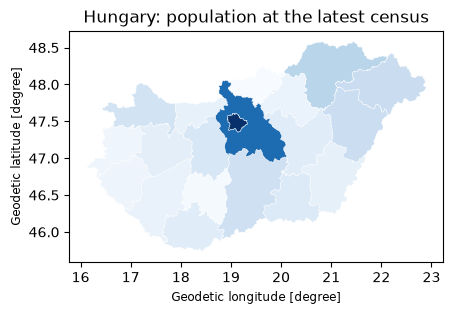

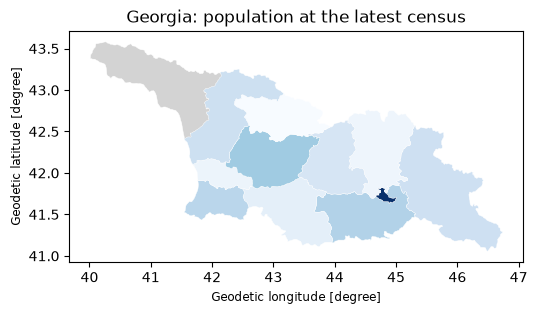

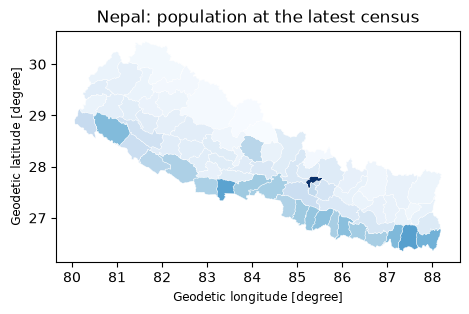

In [29]:
# the country and map key of every region in the census table
census_keys = set(zip(written["Country"], written["Map_key"]))

# the country and map key of every shape on the map
map_keys = set(zip(written_map["Country"], written_map["Map_key"]))

# print the keys found in only one of the two files (both should be empty)
print("in the census table but not on the map:", sorted(census_keys - map_keys))

# print the keys found on the map but not in the census table
print("on the map but not in the census table:", sorted(map_keys - census_keys))

# check: both files have exactly the same 107 keys
assert census_keys == map_keys and len(census_keys) == 107

# print the final result
print("join check passed: 107 regions match one to one")

# the latest total population of each region, to colour the preview map
region_totals = written.groupby(["Country", "Map_key"], as_index=False)["Latest"].sum(min_count=1)

# put the totals onto the map shapes
preview = written_map.merge(region_totals, on=["Country", "Map_key"], how="left")

# draw the three countries side by side, coloured by population, abkhazia in grey (no data)
for country in ("Hungary", "Georgia", "Nepal"):

    # draw one country, with missing data in light grey
    preview[preview["Country"] == country].plot(column="Latest", cmap="Blues", edgecolor="white", linewidth=0.3, missing_kwds={"color": "lightgrey", "label": "no data"}, figsize=(6, 3)).set_title(f"{country}: population at the latest census")

## Result

| File | Content |
|---|---|
| `data/processed/HU-GE-NE_census.csv` | 3 424 rows (Hungary 640, Georgia 384 incl. Abkhazia's 32 empty rows, Nepal 2 400) × 29 columns |
| `data/processed/HU-GE-NE_map.geojson` | 107 simplified shapes (Hungary 20, Georgia 12, Nepal 75) with `Country` and `Map_key` |

**In Tableau:** connect to the map as a *spatial file* and to the census CSV as a *text file*, and relate them on `Country` = `Country` and `Map_key` = `Map_key`.